# LGG Segmentation Dataset

This dataset contains brain MR images together with manual FLAIR abnormality segmentation masks. The images were obtained from The Cancer Imaging Archive (TCIA). They correspond to 110 patients included in The Cancer Genome Atlas (TCGA) lower-grade glioma collection with at least fluid-attenuated inversion recovery (FLAIR) sequence and genomic cluster data available. Tumor genomic clusters and patient data is provided in data.csv file.

All images are provided in `.tif` format with 3 channels per image. 
1. For 101 cases, 3 sequences are available, i.e. pre-contrast, FLAIR, post-contrast (in this order of channels).
2. For 9 cases, post-contrast sequence is missing.
3. For 6 cases, pre-contrast sequence is missing.
4. Missing sequences are replaced with FLAIR sequence to make all images 3-channel.
5. Masks are binary, 1-channel images. They segment FLAIR abnormality present in the FLAIR sequence (available for all cases).

The dataset is organized into 110 folders named after case ID that contains information about source institution. Each folder contains MR images with the following naming convention:

`TCGA_<institution-code>_<patient-id>_<slice-number>.tif`

Corresponding masks have a `_mask` suffix.

In [1]:
import os
from pathlib import Path

import pandas as pd
import numpy as np

In [2]:
data_dir = Path("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m")
csv_path = data_dir / "data.csv"

In [3]:
info_df = pd.read_csv(csv_path)
display(info_df.head())

{key: info_df[key].nunique() for key in info_df.columns}

,Patient,RNASeqCluster,MethylationCluster,miRNACluster,CNCluster,RPPACluster,OncosignCluster,COCCluster,histological_type,neoplasm_histologic_grade,tumor_tissue_site,laterality,tumor_location,gender,age_at_initial_pathologic,race,ethnicity,death01
0,TCGA_CS_4941,2.0,4.0,2,2.0,NaN,3.0,2,1.0,2.0,1.0,3.0,2.0,2.0,67.0,3.0,2.0,1.0
1,TCGA_CS_4942,1.0,5.0,2,1.0,1.0,2.0,1,1.0,2.0,1.0,3.0,2.0,1.0,44.0,2.0,NaN,1.0
2,TCGA_CS_4943,1.0,5.0,2,1.0,2.0,2.0,1,1.0,2.0,1.0,1.0,2.0,2.0,37.0,3.0,NaN,0.0
3,TCGA_CS_4944,NaN,5.0,2,1.0,2.0,1.0,1,1.0,1.0,1.0,3.0,6.0,2.0,50.0,3.0,NaN,0.0
4,TCGA_CS_5393,4.0,5.0,2,1.0,2.0,3.0,1,1.0,2.0,1.0,1.0,6.0,2.0,39.0,3.0,NaN,0.0


{'Patient': 110,
 'RNASeqCluster': 4,
 'MethylationCluster': 5,
 'miRNACluster': 4,
 'CNCluster': 3,
 'RPPACluster': 4,
 'OncosignCluster': 3,
 'COCCluster': 3,
 'histological_type': 3,
 'neoplasm_histologic_grade': 2,
 'tumor_tissue_site': 1,
 'laterality': 3,
 'tumor_location': 5,
 'gender': 2,
 'age_at_initial_pathologic': 45,
 'race': 2,
 'ethnicity': 2,
 'death01': 2}

In [4]:
dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
images_data = []

for dir_name in dirs:
    dir_images = os.listdir(data_dir / dir_name)
    
    for slice_name in dir_images:
        if "mask" in slice_name:
            continue

        masked_slice_name = f"{slice_name[:-4]}_mask.tif"
        images_data.append([dir_name, slice_name, masked_slice_name])

images_df = pd.DataFrame(images_data, columns=["Patient ID", "Image", "Mask"])
images_df.head()

,Patient ID,Image,Mask
0,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_45.tif,TCGA_DU_7010_19860307_45_mask.tif
1,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_57.tif,TCGA_DU_7010_19860307_57_mask.tif
2,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_33.tif,TCGA_DU_7010_19860307_33_mask.tif
3,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_27.tif,TCGA_DU_7010_19860307_27_mask.tif
4,TCGA_DU_7010_19860307,TCGA_DU_7010_19860307_52.tif,TCGA_DU_7010_19860307_52_mask.tif


# Dataset Creation

In [5]:
import cv2
import torch
from torch.utils.data import Dataset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [6]:
class CleanSlicesMRIDataset(Dataset):
  def __init__(
      self,
      root_dir=data_dir,
      tumor_only=True,
      min_tumor_pixels=1,
      expected_channels=3,
      check_unique_channels=True,
  ):
    """Self-contained dataset that identifies patients with complete sequences

    and gathers valid slice-mask pairs.

    Args:
        root_dir (str or Path): Path to the dataset root containing patient
          folders.
        tumor_only (bool): If True, retains only slices containing tumor
          annotations.
        min_tumor_pixels (int): Minimum non-zero mask pixels to consider as
          positive tumor.
        expected_channels (int): Expected number of sequence channels (typically
          3: pre-T1, FLAIR, post-T1).
        check_unique_channels (bool): If True, verifies that channels in sample
          slices are not identical duplicates (ensuring FLAIR was not copied to
          substitute missing sequences).
    """
    self.root_dir = Path(root_dir)
    self.samples = []

    # 1. Discover all patient directories
    patient_dirs = sorted([p for p in self.root_dir.iterdir() if p.is_dir()])
    pbar = tqdm(patient_dirs, desc="Filtering cases")

    for p_dir in pbar:
      # Collect all raw slice files (excluding masks)
      slice_files = sorted(
          [
              f
              for f in p_dir.iterdir()
              if f.suffix.lower() in [".tif", ".tiff", ".png"]
              and "mask" not in f.name
          ],
          key=lambda f: (
              int(f.stem.split("_")[-1])
              if f.stem.split("_")[-1].isdigit()
              else f.name
          ),
      )

      if not slice_files:
        continue

      # 2. Patient-level sequence check: verify images have 3 non-duplicate channels
      if check_unique_channels:
        # Check a representative slice near the middle of the stack
        sample_slice_path = slice_files[len(slice_files) // 2]
        sample_img = cv2.imread(str(sample_slice_path), cv2.IMREAD_UNCHANGED)

        if sample_img is None or sample_img.ndim != 3:
          continue
        if sample_img.shape[2] != expected_channels:
          continue

        # If a sequence was missing and substituted by duplicating another channel,
        # channel diffs will be completely identical across the slice.
        c0, c1, c2 = (
            sample_img[:, :, 0],
            sample_img[:, :, 1],
            sample_img[:, :, 2],
        )
        if np.array_equal(c0, c1) or np.array_equal(c1, c2):
          continue

      # 3. Slice-level validation: match slice with mask and filter
      for slice_path in slice_files:
        mask_path = p_dir / f"{slice_path.stem}_mask{slice_path.suffix}"
        if not mask_path.exists():
          continue

        if tumor_only:
          # Check mask directly from disk
          mask_preview = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
          if (
              mask_preview is None
              or np.count_nonzero(mask_preview) < min_tumor_pixels
          ):
            continue

        self.samples.append((slice_path, mask_path))

  def __len__(self):
    return len(self.samples)

  def __getitem__(self, idx):
    slice_path, mask_path = self.samples[idx]

    # Load image (H, W, C) and mask (H, W)
    image = cv2.imread(str(slice_path), cv2.IMREAD_UNCHANGED) / 255.0
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) / 255.0

    # Format to PyTorch tensors: (C, H, W) and (1, H, W)
    image = torch.from_numpy(image).float().permute(2, 0, 1)
    mask = torch.from_numpy(mask).float().unsqueeze(0)

    return image, mask

# EDA

In [7]:
def plot_mri_images(mri_slice, mask):
    fig, axes = plt.subplots(1,2,figsize=(10,5))
    
    axes[0].imshow(mri_slice.permute(1,2,0))
    axes[1].imshow(mask.permute(1,2,0), cmap="gray")

    axes[0].axis("off")
    axes[1].axis("off")

    axes[0].set_title(f"MRI Slice")
    axes[1].set_title(f"Tumor Mask")
        
    plt.show()

In [8]:
clean_slices_mri_ds = CleanSlicesMRIDataset()

Filtering cases:   0%|          | 0/110 [00:00<?, ?it/s]

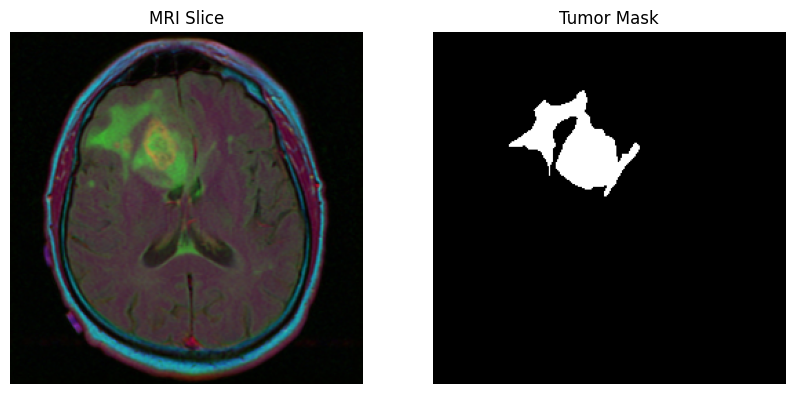

In [9]:
mri_slice, mask = clean_slices_mri_ds[3]
plot_mri_images(mri_slice, mask)

# Comparing Cohen's d

In [10]:
import scipy.ndimage as ndi

In [11]:
def get_clean_brain_mask(slice_2d, thresh=0.05):
    """Extracts contiguous head/brain mask and removes air noise."""
    arr = slice_2d.detach().cpu().numpy()
    opened = ndi.binary_opening(arr > thresh, structure=np.ones((3, 3)))
    labels, _ = ndi.label(opened)
    largest = labels == (np.bincount(labels.flat)[1:].argmax() + 1)
    return ndi.binary_fill_holes(largest)

def calc_cohen_d(mri_slice, mask, thresh=0.05, channel=None):
    t_mask = (mask > 0).squeeze().cpu().numpy()
    b_mask = get_clean_brain_mask(mri_slice[0], thresh)
    h_mask = b_mask & (~t_mask)

    if channel is not None:
        t_vox = mri_slice[channel, t_mask]
        h_vox = mri_slice[channel, h_mask]
    else:
        t_vox = mri_slice[:, t_mask]
        h_vox = mri_slice[:, h_mask]
    
    mu_t, std_t = t_vox.mean(), t_vox.std()
    mu_h, std_h = h_vox.mean(), h_vox.std()
    
    # s_pooled calculation
    n1 = t_vox.numel()
    n2 = h_vox.numel()
    s_pooled_num   = (n1 - 1) * (std_t)**2 + (n2 - 1) * (std_h)**2
    s_pooled_denom = n1 + n2 - 2
    s_pooled = torch.sqrt(s_pooled_num / s_pooled_denom)
    
    # Cohen's d
    d = (mu_t - mu_h) / s_pooled
    return d.item()

for channel in [None, 0, 1, 2]:
    print(f"Cohen's d for channel={channel}, {calc_cohen_d(mri_slice, mask, channel=channel):.4f}")

Cohen's d for channel=None, 1.1542
Cohen's d for channel=0, 1.2061
Cohen's d for channel=1, 2.3871
Cohen's d for channel=2, 0.1128


# Testing Image Transformations